In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms

from plot_style import C, apply

FIG = Path("figs")
DATA_PATH = FIG / "data" / "threshold_sharpen_data.npz"
OUTPUT = FIG / "Fig5.pdf"

apply()

with np.load(DATA_PATH) as archive:
    data = {name: archive[name] for name in archive.files}

In [2]:
def panel_label(ax, label, dx_pt=-12.0, dy_pt=4.0, fontsize=8.6):
    transform = ax.transAxes + mtransforms.ScaledTranslation(
        dx_pt / 72.0, dy_pt / 72.0, ax.figure.dpi_scale_trans
    )
    ax.text(
        0.0, 1.0, label, transform=transform, ha="left", va="bottom",
        fontsize=fontsize, fontweight="bold", color="#222222",
        clip_on=False, zorder=30,
    )

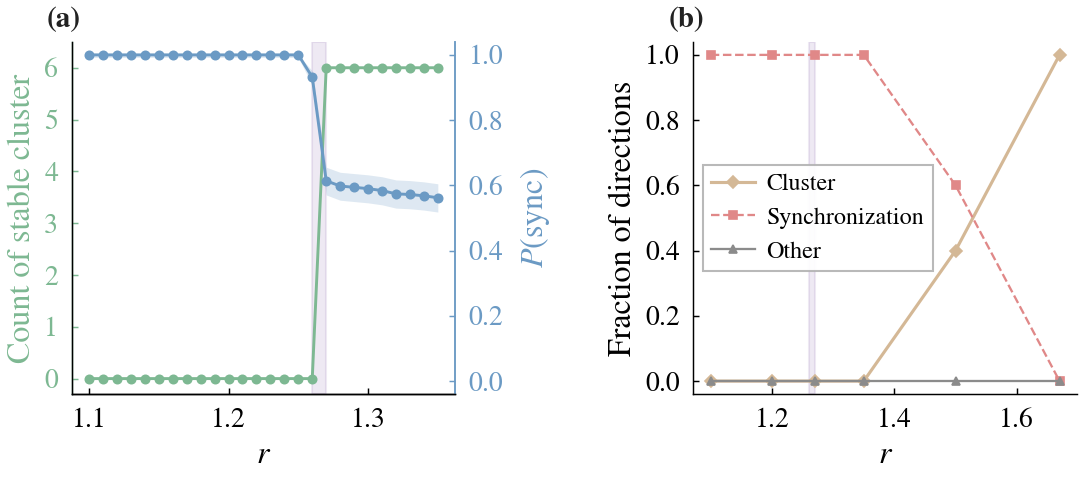

In [3]:
ratios = data["ratios"]
n_stable = data["n_stable"]
basin_p = data["basin_p"]
basin_lo = data["basin_lo"]
basin_hi = data["basin_hi"]
scan_r = data["scan_r"]
scan_sink = data["scan_sink"]
scan_inphase = data["scan_inphase"]
scan_other = data["scan_other"]
r_onset_lo, r_onset_hi = data["r_onset_ci"]

fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.35), constrained_layout=False)

LABEL_FS = 11.0 * 1.4
TICK_FS = 9.5 * 1.4
LEGEND_FS = 9.6 * 1.2

ax_count = ax[0]
ax_basin = ax_count.twinx()

ax_count.plot(ratios, n_stable, "o-", color=C["green"], ms=4, lw=1.4)
ax_count.axvspan(r_onset_lo, r_onset_hi, alpha=0.18, color=C["purple"])
ax_basin.fill_between(ratios, basin_lo, basin_hi, color=C["blue"], alpha=0.22, lw=0)
ax_basin.plot(ratios, basin_p, "o-", color=C["blue"], ms=4, lw=1.4)

ax_count.set_xlabel(r"$r$", fontsize=LABEL_FS)
ax_count.set_ylabel(r"Count of stable cluster", color=C["green"], fontsize=LABEL_FS)
ax_basin.set_ylabel(r"$P(\mathrm{sync})$", color=C["blue"], fontsize=LABEL_FS,
                    labelpad=7.0)
ax_count.set_ylim(-0.3, 6.5)
ax_count.set_yticks([0, 1, 2, 3, 4, 5, 6])
ax_basin.set_ylim(-0.04, 1.04)
ax_basin.set_yticks(np.linspace(0, 1, 6))
ax_count.spines["left"].set_color(C["green"])
ax_basin.spines["right"].set_visible(True)
ax_basin.spines["right"].set_color(C["blue"])
ax_basin.spines["right"].set_linewidth(0.9)
ax_basin.yaxis.set_label_position("right")
ax_basin.yaxis.tick_right()
ax_basin.patch.set_visible(False)

ax_out = ax[1]
ax_out.plot(scan_r, scan_sink, "D-", color=C["sand"], ms=4, lw=1.5, label="Cluster")
ax_out.plot(scan_r, scan_inphase, "s--", color=C["red"], ms=3.5, lw=1.1,
            label="Synchronization")
ax_out.plot(scan_r, scan_other, "^-", color=C["gray"], ms=3.5, lw=1.1, label="Other")
ax_out.axvspan(r_onset_lo, r_onset_hi, alpha=0.18, color=C["purple"])
ax_out.set_xlabel(r"$r$", fontsize=LABEL_FS)
ax_out.set_ylabel("Fraction of directions", fontsize=LABEL_FS)
ax_out.set_ylim(-0.04, 1.04)
ax_out.legend(loc="center left", fontsize=LEGEND_FS)

for i, axis in enumerate(ax):
    axis.tick_params(axis="both", which="major", labelsize=TICK_FS, direction="in", pad=6.5)
    panel_label(axis, f"({chr(97 + i)})", fontsize=14)

ax_count.tick_params(axis="y", colors=C["green"])
ax_basin.tick_params(axis="y", which="major", labelsize=TICK_FS, colors=C["blue"], direction="in", pad=6.5)

fig.tight_layout(w_pad=3.0)
fig.savefig(OUTPUT)
plt.show()